# Task 1
## Statement of AI use :
AI was used by the group to set up and understand the jupyter notebook, since we have never used a similar environment before. 
It was also used for getting clearer plottings when the result was not shown good enough. One example was how to make "linestyle='--'" which we have used in a previous course, but could not remember how to apply.


## Task 1a

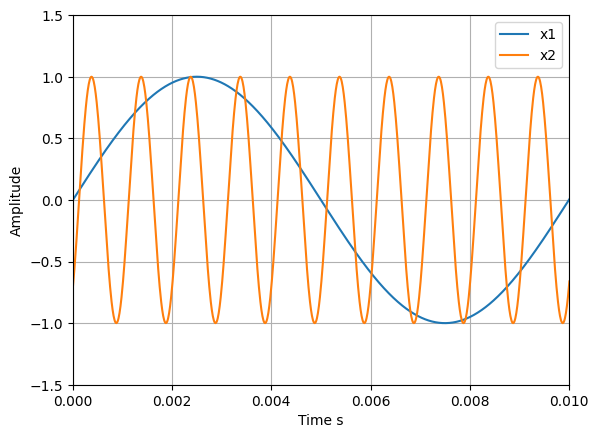

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import sounddevice as sd

# Generate a time vector ’t’ and the incrementing ∆t = 0,01ms = 0,00001s as suggested in the assignment
dt = 0.00001
t = np.arange(0, 5, dt)

## For x1: period T=0.01s, amplitude A=1, phase shift φ = 0 and f= 1/T = 1/0,01 = 100Hz
## For x2: amplitude A=1, phase shift φ = -pi/4 and f=1000Hz
x1 = 1*np.sin(2*np.pi*100*t+0)
x2 = 1*np.sin(2*np.pi*1000*t-np.pi/4)

# Create a new figure
fig, ax = plt.subplots()

ax.plot(t, x1, label='x1')
ax.plot(t, x2, label='x2')
ax.set_xlabel('Time s')
ax.set_ylabel('Amplitude')
ax.set_xlim(0, 0.01)
ax.set_ylim(-1.5 , 1.5)

ax.legend()
ax.grid()

plt.show()

sd.play(x1 ,1/dt ,blocking=True)
sd.play(x2 ,1/dt ,blocking=True)


### Explanation of plot of 1a
This plot shows x1(t) (100Hz) and x2(t) (1000Hz). Because x2(t) has ten times the frequency of x1(t),it completes ten full periods within the time window, while x1(t) completes only one. Both waves maintain a peak amplitude of 1.

## Task 1b
The two generated signals differ noticeably in perceived acoustic pitch. The first signal (x1, 100Hz) produces a low, dark hum similar to the sound of a refrigerator. In contrast, the second signal (x2, 1000Hz) produces a much higher-pitched tone, resembling a classic telephone dial tone. Mathematically, frequency f represents the number of full oscillation cycles per second (f = 1/T). Because the 1000Hz signal completes ten times more cycles per second than the 100Hz signal, the sound wave oscillates much faster, which our ears pick up as a higher pitch.

# Task 2

## Task 2a and b

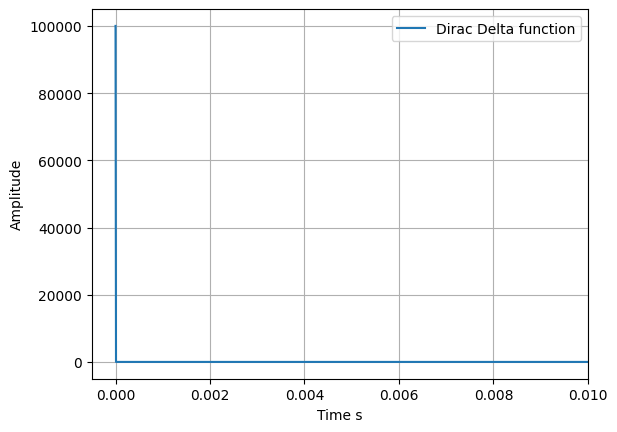

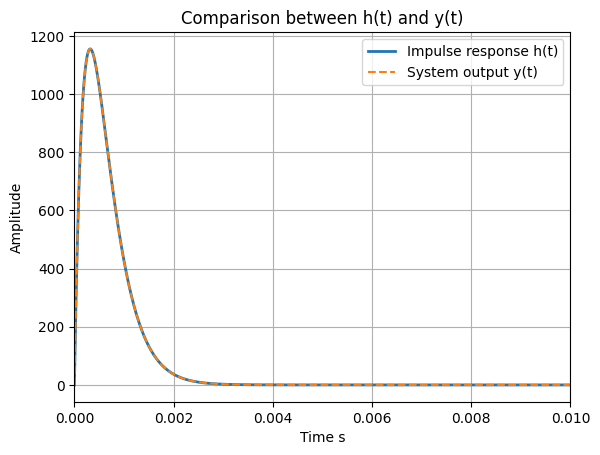

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import sounddevice as sd

dt = 0.00001
t2 = np.arange(0, 0.01, dt)

def convolve(x, h):
    y = dt*signal.convolve(x, h, method = 'direct')
    y = y[0:x.shape[0]]
    return y

# Approximation of Dirac Delta
d = np.zeros(t2.shape)
d[0] = 1/dt

alpha = 1000 * np.pi
h = (alpha**2)*t2*np.exp(-alpha*t2)
y = convolve(d, h) 

# Plotting Dirac Delta function d(t)
fig, ax1 = plt.subplots()
ax1.plot(t2, d, label='Dirac Delta function')

ax1.set_xlabel('Time s')
ax1.set_ylabel('Amplitude')
ax1.set_xlim(-0.0005, 0.01)
ax1.set_ylim(-5000, 105000)
ax1.legend()
ax1.grid()
plt.show()

# Plotting output y(t) together with impulse response h(t)
fig2, ax2 = plt.subplots()
ax2.plot(t2, h, label='Impulse response h(t)', linewidth=2)
ax2.plot(t2, y, label='System output y(t)', linestyle='--')

ax2.set_xlabel('Time s')
ax2.set_ylabel('Amplitude')
ax2.set_title('Comparison between h(t) and y(t)')
ax2.set_xlim(0, 0.01)
ax2.legend()
ax2.grid(True)
plt.show()


### Explanation of Dirac delta function and output-impulse response plot

When plotting the Dirac delta function we got the characteristic "L-shaped" plot, which was shown in previous lectures. This is because the Dirac delta function is approximated as a pulse at t = 0 with an amplitude of 1/Δt and zero elsewhere, creating a sharp spike at the origin followed by zero for all t > 0, where the height of 1/Δt normalizes the area under the pulse to 1.

When analyzing the output and impulse response plot, we can see that they are identical. The definition of impulse response and input-output relationships is that with an input x(t) is equal to the dirac delta funtion, which is called the system's impulse response h(t) (x(t)=δ(t) -> y(t)=h(t)). This would explain why y(t) is equal to h(t). 

## Task 2c and d

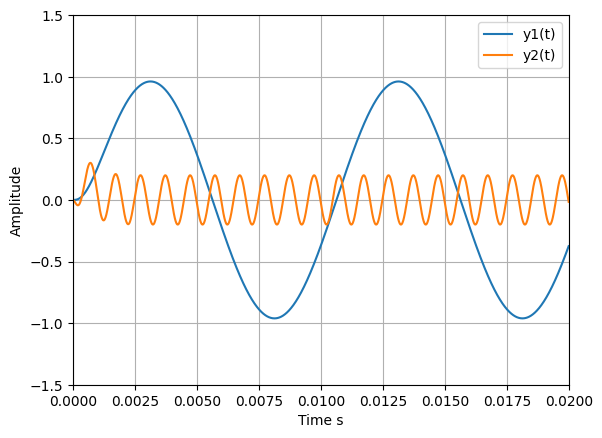

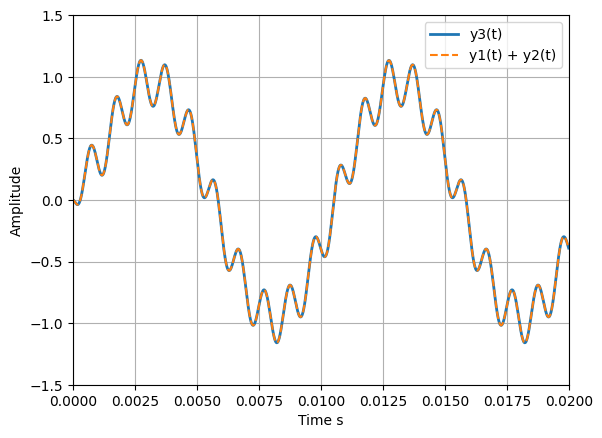

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import sounddevice as sd

dt = 0.00001
t3 = np.arange(0, 0.02, dt)

# Retrieved from Task 1
## For x1: period T=0.01s, amplitude A=1, phase shift φ = 0 and f= 1/T = 1/0,01 = 100Hz
## For x2: amplitude A=1, phase shift φ = -pi/4 and f=1000Hz
x1 = 1*np.sin(2*np.pi*100*t3+0)
x2 = 1*np.sin(2*np.pi*1000*t3-np.pi/4)

x3 = x1 + x2

def convolve(x, h):
    y = dt*signal.convolve(x, h, method = 'direct')
    y = y[0:x.shape[0]]
    return y

alpha = 1000 * np.pi
h = (alpha**2)*t3*np.exp(-alpha*t3)
y1 = convolve(x1, h) 
y2 = convolve(x2, h)

y3 = convolve(x3, h)
ySum = y1 + y2

# Plotting y1(t) and y2(t)
fig, ax1 = plt.subplots()
ax1.plot(t3, y1, label='y1(t)')
ax1.plot(t3, y2, label='y2(t)')

ax1.set_xlabel('Time s')
ax1.set_ylabel('Amplitude')
ax1.set_xlim(0, 0.02) 
ax1.set_ylim(-1.5, 1.5)
ax1.legend()
ax1.grid()
plt.show()

# Plotting y3(t)
fig, ax2 = plt.subplots()
ax2.plot(t3, y3, label='y3(t)', linewidth=2)
ax2.plot(t3, ySum, label='y1(t) + y2(t)', linestyle='--')

ax2.set_xlabel('Time s')
ax2.set_ylabel('Amplitude')
ax2.set_xlim(0, 0.02) 
ax2.set_ylim(-1.5, 1.5)
ax2.legend()
ax2.grid()
plt.show()


### Explanation of y1(t) and y2(t)
The plot shows the outputs of the convolution of h(t) and the two different inputs x1(t) and x2(t). Analyzing the plot, we can observe that the output of the two signals differ. What has not changed is that the outputs are both sinus functions. This is because of the sine-in, sine-out principle. We can also see that the frequency (period) has not changed from what we observed in task 1. However, what has changed is the amplitude and the phase shift. This is becuase in LTI system the amplitude and phase of sinus signals is based on their frequency response. Signal x2, with a higher frequency (1000Hz) experiences a much stronger amplitude reduction than x1, which has a lower frequency (100Hz). This shows that the system acts as a low-pass filter. 

### Explanation of y3(t) and sums of y1(t) and y2(t)
In subtask d we plotted the sum and the inputs x1(t) and x2(t) which we called x3(t). This is what gave the output y3(t) via convolution seen in the plot. Additionally, we added the outputs y1(t) and y2(t) conducted in task 2c. As seen in the plot, the two curves overlap perfectly. This demonstrates the linearity principle (superposition property) of continuous-time LTI systems(α*x1(t)+β*x2(t) -> α*y1(t)+β*y2(t)). Since y3(t) = y1(t) + y2(t) when α=1 and β=1, our numerical result confirms that the system is linear.

